# 06 — Cross-Dataset Comparison: **Georgia 12-Lead ECG** vs. All Other ECG Datasets

This notebook benchmarks **Georgia 12-Lead ECG** (`georgia_ecg/`) against the other four clinical 12-lead ECG datasets in this repository (**PTB-XL**, **MIMIC-IV-ECG**, **Georgia 12-Lead ECG**, **Chapman-Shaoxing**, and **CODE-15%**):

1. **Cohort Scale & Quality-Tier Overview** — Record counts, patient multiplicity, sampling rates, and `0_clean`–`3_severe_error` distributions with **Georgia 12-Lead ECG** highlighted.
2. **Demographics Comparison** — Age distributions, pediatric rates, and sex ratios across cohorts.
3. **Waveform Amplitude, Einthoven Physics & Power Spectral Density (PSD)** — Stratified clean-record signal comparison (`N = 80` clean ECGs per dataset), exposing `50 Hz` vs `60 Hz` mains hum and hardware scaling differences.
4. **Error Taxonomy & Multi-Source Transfer Implications** — Side-by-side audit of universal quality dimensions and practical harmonization steps when combining **Georgia 12-Lead ECG** with peer cohorts.
5. **Representative Clean Lead-II Waveform Gallery** — Visual side-by-side comparison of clean `0–5 s` Lead-II strips across all five datasets.


In [1]:
import warnings
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb
from scipy.signal import welch

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

TARGET_KEY = "georgia_ecg"
TARGET_NAME = "Georgia 12-Lead ECG"

_cwd = Path.cwd().resolve()
for _cand in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_cand / "ptbxl" / "quality" / "error_labels.csv").exists():
        REPO_ROOT = _cand
        break
else:
    raise FileNotFoundError(f"Could not locate repository root from {_cwd}")

DATASET_META = [
    {
        "key": "ptbxl",
        "name": "PTB-XL",
        "err_path": REPO_ROOT / "ptbxl" / "quality" / "error_labels.csv",
        "fs": 500,
        "duration_s": 10.0,
        "mains_hz": 50,
        "region": "Germany",
        "taxonomy": "SCP-ECG (71 codes)",
    },
    {
        "key": "mimic_iv_ecg",
        "name": "MIMIC-IV-ECG",
        "err_path": REPO_ROOT / "mimic_iv_ecg" / "quality" / "error_labels.csv.gz",
        "fs": 500,
        "duration_s": 10.0,
        "mains_hz": 60,
        "region": "USA (BIDMC)",
        "taxonomy": "Free-text reports",
    },
    {
        "key": "georgia_ecg",
        "name": "Georgia ECG",
        "err_path": REPO_ROOT / "georgia_ecg" / "quality" / "error_labels.csv",
        "fs": 500,
        "duration_s": 10.0,
        "mains_hz": 60,
        "region": "USA (Emory)",
        "taxonomy": "SNOMED-CT (CinC 2020)",
    },
    {
        "key": "chapman_shaoxing",
        "name": "Chapman-Shaoxing",
        "err_path": REPO_ROOT / "chapman_shaoxing" / "quality" / "error_labels.csv",
        "fs": 500,
        "duration_s": 10.0,
        "mains_hz": 50,
        "region": "China",
        "taxonomy": "SNOMED-CT (63+ codes)",
    },
    {
        "key": "code15",
        "name": "CODE-15%",
        "err_path": REPO_ROOT / "code15" / "quality" / "error_labels.csv.gz",
        "fs": 400,
        "duration_s": 10.24,
        "mains_hz": 60,
        "region": "Brazil",
        "taxonomy": "6 binary labels",
    },
]

ORDER = [TARGET_KEY] + [d["key"] for d in DATASET_META if d["key"] != TARGET_KEY]
META_BY_KEY = {d["key"]: d for d in DATASET_META}
NAME_BY_KEY = {d["key"]: d["name"] for d in DATASET_META}

HIGHLIGHT_COLOR = "#d62728"
PEER_COLOR = "#4c78a8"
PALETTE = {k: (HIGHLIGHT_COLOR if k == TARGET_KEY else PEER_COLOR) for k in ORDER}

err_tables = {}
for k in ORDER:
    err_tables[k] = pd.read_csv(META_BY_KEY[k]["err_path"])

print(f"Loaded error_labels tables for all 5 datasets (spotlight: {TARGET_NAME}).")


Loaded error_labels tables for all 5 datasets (spotlight: Georgia 12-Lead ECG).


## 1. Cohort Scale & Quality-Tier Overview (**Georgia 12-Lead ECG** vs. Peers)

Comparing total audited records, unique patients, sampling rate, and `0_clean` / `1_minor_warning` / `2_moderate_anomaly` / `3_severe_error` proportions across all five benchmarks.

,Dataset,Records,Patients,Recs/Pat,Fs (Hz),Mains (Hz),Error Flags,0_clean %,1_minor %,2_moderate %,3_severe %,Taxonomy
0,★ Georgia ECG,10344,10344,1.00,500,60,18,84.8,9.1,5.6,0.5,SNOMED-CT (CinC 2020)
1,PTB-XL,21799,18869,1.16,500,50,24,46.6,36.9,12.4,4.2,SCP-ECG (71 codes)
2,MIMIC-IV-ECG,800035,161352,4.96,500,60,15,52.7,41.7,0.9,4.7,Free-text reports
3,Chapman-Shaoxing,45053,45053,1.00,500,50,10,65.9,3.9,29.5,0.7,SNOMED-CT (63+ codes)
4,CODE-15%,345779,233770,1.48,400,60,12,23.1,45.7,0.6,30.6,6 binary labels


Spotlight (Georgia 12-Lead ECG): 10,344 records (peer median: 195,416) | 0_clean=84.8% (peer median: 49.7%) | 3_severe=0.5% (peer median: 4.5%)


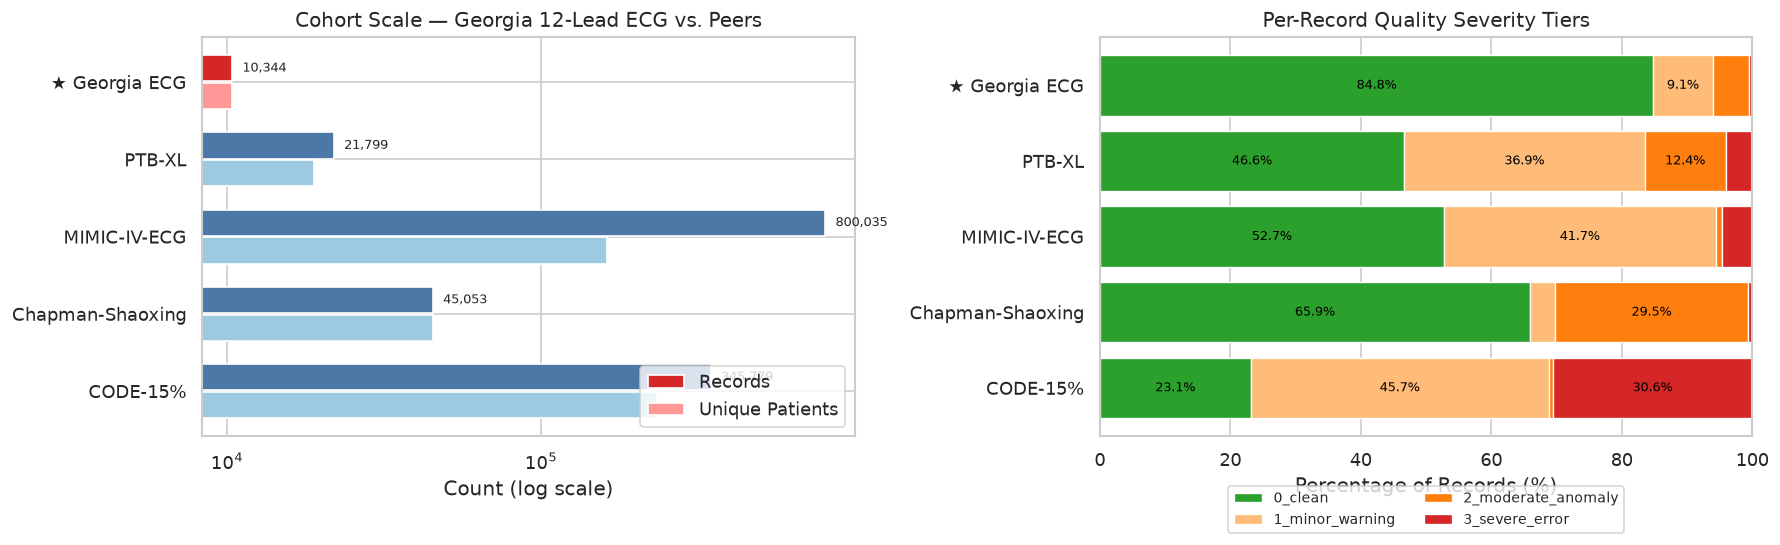

In [2]:
ptbxl_db = pd.read_csv(REPO_ROOT / "ptbxl" / "data" / "ptbxl_database.csv", usecols=["ecg_id", "patient_id", "age", "sex", "filename_hr"])
code15_exams = pd.read_csv(REPO_ROOT / "code15" / "data" / "exams.csv", usecols=["exam_id", "patient_id", "age", "is_male", "trace_file"])

patient_counts = {
    "ptbxl": int(ptbxl_db["patient_id"].nunique()),
    "mimic_iv_ecg": int(err_tables["mimic_iv_ecg"]["subject_id"].nunique()),
    "georgia_ecg": int(len(err_tables["georgia_ecg"])),       # 1 record per patient in CinC 2020 Georgia
    "chapman_shaoxing": int(len(err_tables["chapman_shaoxing"])),  # 1 record per patient
    "code15": int(code15_exams["patient_id"].nunique()),
}

summary_rows = []
for k in ORDER:
    df = err_tables[k]
    n = len(df)
    n_pat = patient_counts[k]
    tiers = df["severity_tier"].value_counts()
    n_flags = sum(c.startswith("err_") for c in df.columns)
    summary_rows.append({
        "Dataset": f"★ {NAME_BY_KEY[k]}" if k == TARGET_KEY else NAME_BY_KEY[k],
        "Records": n,
        "Patients": n_pat,
        "Recs/Pat": round(n / n_pat, 2),
        "Fs (Hz)": META_BY_KEY[k]["fs"],
        "Mains (Hz)": META_BY_KEY[k]["mains_hz"],
        "Error Flags": n_flags,
        "0_clean %": round(100 * tiers.get("0_clean", 0) / n, 1),
        "1_minor %": round(100 * tiers.get("1_minor_warning", 0) / n, 1),
        "2_moderate %": round(100 * tiers.get("2_moderate_anomaly", 0) / n, 1),
        "3_severe %": round(100 * tiers.get("3_severe_error", 0) / n, 1),
        "Taxonomy": META_BY_KEY[k]["taxonomy"],
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

# Highlight delta vs peer median
target_row = summary_df.iloc[0]
peer_df = summary_df.iloc[1:]
print(
    f"Spotlight ({TARGET_NAME}): {target_row['Records']:,} records "
    f"(peer median: {int(peer_df['Records'].median()):,}) | "
    f"0_clean={target_row['0_clean %']:.1f}% (peer median: {peer_df['0_clean %'].median():.1f}%) | "
    f"3_severe={target_row['3_severe %']:.1f}% (peer median: {peer_df['3_severe %'].median():.1f}%)"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
labels = [summary_df.loc[i, "Dataset"] for i in range(len(summary_df))]
y = np.arange(len(labels))

# Panel A: Log-scale Records vs Patients
axes[0].barh(y - 0.18, summary_df["Records"], height=0.34,
             color=[HIGHLIGHT_COLOR if k == TARGET_KEY else PEER_COLOR for k in ORDER], label="Records")
axes[0].barh(y + 0.18, summary_df["Patients"], height=0.34,
             color=["#ff9896" if k == TARGET_KEY else "#9ecae1" for k in ORDER], label="Unique Patients")
axes[0].set_xscale("log")
axes[0].set_yticks(y)
axes[0].set_yticklabels(labels)
axes[0].invert_yaxis()
axes[0].set_xlabel("Count (log scale)")
axes[0].set_title(f"Cohort Scale — {TARGET_NAME} vs. Peers")
axes[0].legend(loc="lower right")
for i, (r, p) in enumerate(zip(summary_df["Records"], summary_df["Patients"])):
    axes[0].text(r * 1.08, i - 0.18, f"{r:,}", va="center", fontsize=8)

# Panel B: 100% stacked severity tiers
tier_cols = ["0_clean %", "1_minor %", "2_moderate %", "3_severe %"]
tier_colors = ["#2ca02c", "#ffbb78", "#ff7f0e", "#d62728"]
tier_names = ["0_clean", "1_minor_warning", "2_moderate_anomaly", "3_severe_error"]
left = np.zeros(len(summary_df))
for col, c, tname in zip(tier_cols, tier_colors, tier_names):
    vals = summary_df[col].to_numpy()
    axes[1].barh(y, vals, left=left, color=c, edgecolor="white", linewidth=0.8, label=tname)
    for i, v in enumerate(vals):
        if v >= 7.5:
            axes[1].text(left[i] + v / 2, i, f"{v:.1f}%", ha="center", va="center", fontsize=8, color="black")
    left += vals
axes[1].set_yticks(y)
axes[1].set_yticklabels(labels)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Percentage of Records (%)")
axes[1].set_title("Per-Record Quality Severity Tiers")
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.26), ncol=2, fontsize=8.5)

plt.tight_layout()
plt.show()


## 2. Demographics Comparison (Age & Sex)

Comparing valid clinical age distributions (`1–100 yr`, excluding PTB-XL's `age == 300` HIPAA sentinel) and sex balance across datasets. *(Note: MIMIC-IV-ECG standalone WFDB tables do not include age/sex; those live in the separate MIMIC-IV Clinical database.)*

,Dataset,Valid Ages,Mean Age,Median Age,IQR (25–75%),Pediatric (<18) %,Male %
0,★ Georgia ECG,10257,60.5,62.0,51–72,0.03,53.6
1,PTB-XL,21506,59.5,61.0,50–72,0.62,52.1
2,MIMIC-IV-ECG,0,NaN,NaN,N/A (MIMIC-IV Clinical),0.09,NaN
3,Chapman-Shaoxing,44433,58.5,62.0,48–72,4.15,56.0
4,CODE-15%,345779,53.2,54.0,37–70,1.15,40.3


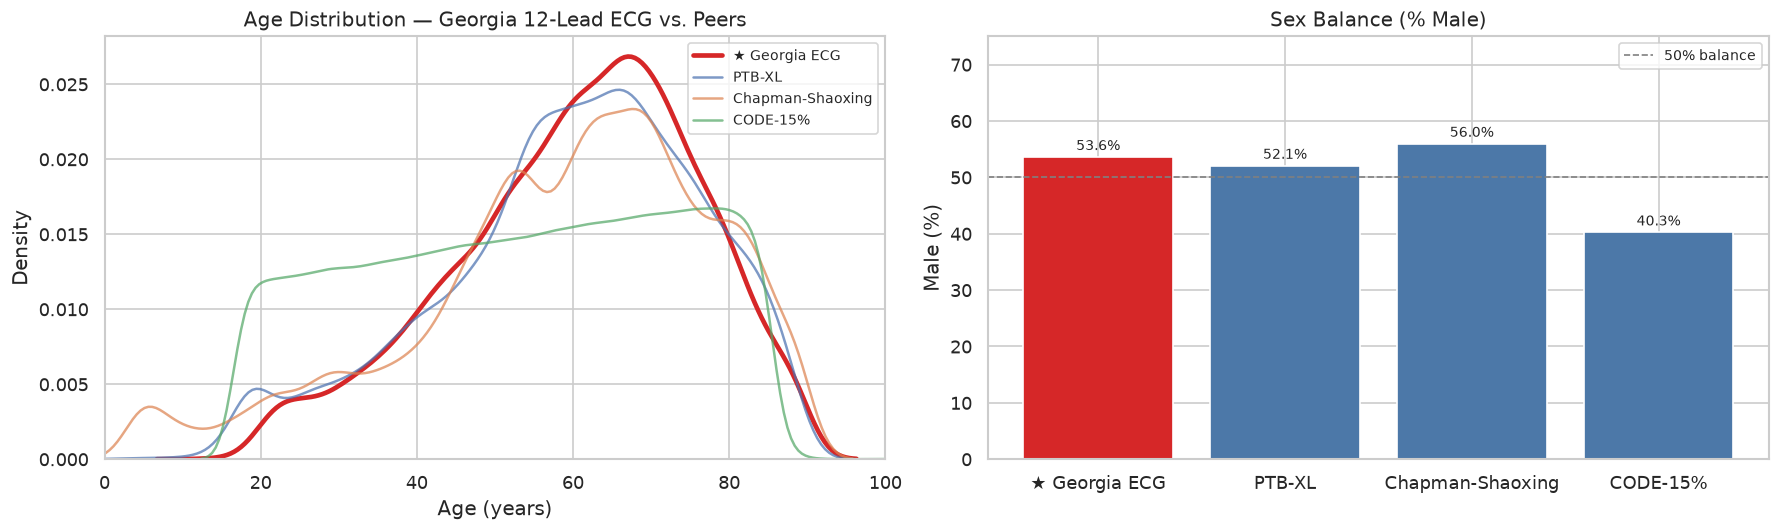

In [3]:
demo_age = {}
demo_male_pct = {}

# PTB-XL: sex 0=Male, 1=Female; age 300 is >89 sentinel
ptb_age = ptbxl_db["age"].dropna()
ptb_age = ptb_age[(ptb_age > 0) & (ptb_age <= 100)]
demo_age["ptbxl"] = ptb_age.to_numpy()
demo_male_pct["ptbxl"] = float(100 * (ptbxl_db["sex"] == 0).mean())

# Georgia
g_df = err_tables["georgia_ecg"]
g_age = pd.to_numeric(g_df["age"], errors="coerce").dropna()
g_age = g_age[(g_age > 0) & (g_age <= 100)]
demo_age["georgia_ecg"] = g_age.to_numpy()
demo_male_pct["georgia_ecg"] = float(100 * (g_df["sex"].astype(str).str.lower().str.startswith("m")).mean())

# Chapman-Shaoxing
c_df = err_tables["chapman_shaoxing"]
c_age = pd.to_numeric(c_df["age"], errors="coerce").dropna()
c_age = c_age[(c_age > 0) & (c_age <= 100)]
demo_age["chapman_shaoxing"] = c_age.to_numpy()
demo_male_pct["chapman_shaoxing"] = float(100 * (c_df["sex"].astype(str).str.lower().str.startswith("m")).mean())

# CODE-15%
k_age = pd.to_numeric(code15_exams["age"], errors="coerce").dropna()
k_age = k_age[(k_age > 0) & (k_age <= 100)]
demo_age["code15"] = k_age.to_numpy()
demo_male_pct["code15"] = float(100 * code15_exams["is_male"].astype(bool).mean())

demo_rows = []
for k in ORDER:
    if k in demo_age:
        arr = demo_age[k]
        demo_rows.append({
            "Dataset": f"★ {NAME_BY_KEY[k]}" if k == TARGET_KEY else NAME_BY_KEY[k],
            "Valid Ages": len(arr),
            "Mean Age": round(float(np.mean(arr)), 1),
            "Median Age": round(float(np.median(arr)), 1),
            "IQR (25–75%)": f"{np.percentile(arr, 25):.0f}–{np.percentile(arr, 75):.0f}",
            "Pediatric (<18) %": round(float(100 * np.mean(arr < 18)), 2),
            "Male %": round(demo_male_pct[k], 1),
        })
    else:
        demo_rows.append({
            "Dataset": f"★ {NAME_BY_KEY[k]}" if k == TARGET_KEY else NAME_BY_KEY[k],
            "Valid Ages": 0,
            "Mean Age": np.nan,
            "Median Age": np.nan,
            "IQR (25–75%)": "N/A (MIMIC-IV Clinical)",
            "Pediatric (<18) %": round(float(100 * err_tables[k]["err_rep_pediatric"].mean()), 2),
            "Male %": np.nan,
        })
display(pd.DataFrame(demo_rows))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
age_keys = [k for k in ORDER if k in demo_age]

for k in age_keys:
    is_t = (k == TARGET_KEY)
    sns.kdeplot(
        demo_age[k], ax=axes[0],
        label=f"★ {NAME_BY_KEY[k]}" if is_t else NAME_BY_KEY[k],
        color=HIGHLIGHT_COLOR if is_t else None,
        linewidth=2.8 if is_t else 1.5,
        alpha=1.0 if is_t else 0.72,
    )
axes[0].set_xlim(0, 100)
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Density")
axes[0].set_title(f"Age Distribution — {TARGET_NAME} vs. Peers")
axes[0].legend(fontsize=8.5)

male_vals = [demo_male_pct[k] for k in age_keys]
lbls = [f"★ {NAME_BY_KEY[k]}" if k == TARGET_KEY else NAME_BY_KEY[k] for k in age_keys]
bars = axes[1].bar(lbls, male_vals, color=[HIGHLIGHT_COLOR if k == TARGET_KEY else PEER_COLOR for k in age_keys])
axes[1].axhline(50, color="gray", ls="--", lw=1.0, label="50% balance")
axes[1].set_ylim(0, 75)
axes[1].set_ylabel("Male (%)")
axes[1].set_title("Sex Balance (% Male)")
for b, v in zip(bars, male_vals):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 1.2, f"{v:.1f}%", ha="center", fontsize=8.5)
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()


## 3. Signal Amplitude, Einthoven Physics & Power Spectral Density (`N = 80` Clean ECGs / Dataset)

Direct waveform comparison on a deterministic random sample of `80` `0_clean` recordings per dataset:
- **Lead II RMS & Peak-to-Peak Amplitude (mV)** — checks voltage/gain consistency across acquisition devices.
- **Einthoven Residual (`RMSE(II - (I + III))`)** — checks lead-vector mathematical consistency.
- **Normalized Welch Power Spectral Density (`0.5–80 Hz`)** — directly visualizes `50 Hz` (Germany/China) vs `60 Hz` (USA/Brazil) mains interference and hardware low-pass filtering.

,N,Median_RMS_II_mV,Median_PtP_II_mV,Median_Einthoven_RMSE_mV
Dataset,,,,
★ Georgia ECG,80,0.1484,0.9945,0.0007
PTB-XL,80,0.1353,0.9245,0.0004
MIMIC-IV-ECG,79,0.1163,0.8150,0.0051
Chapman-Shaoxing,80,0.1319,0.9050,0.0005
CODE-15%,80,0.3316,2.2391,0.0000


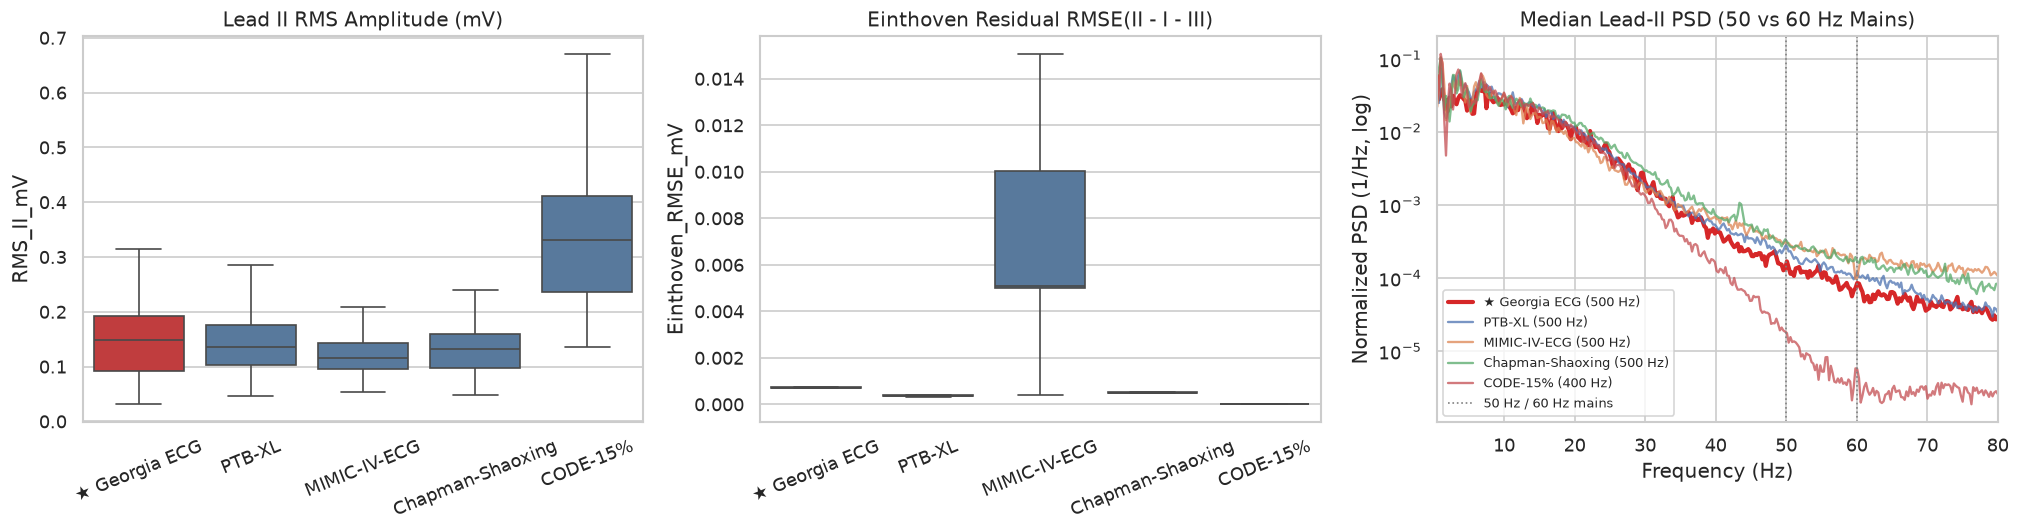

In [4]:
N_SAMPLE = 80
RNG = np.random.default_rng(42)

def sample_waveforms(key: str, n: int = N_SAMPLE):
    '''Return list of (signal_12xT_mv, fs, record_label) for n clean records.'''
    out = []
    if key == "ptbxl":
        clean_ids = set(err_tables["ptbxl"].loc[err_tables["ptbxl"]["severity_tier"] == "0_clean", "ecg_id"])
        sub = ptbxl_db[ptbxl_db["ecg_id"].isin(clean_ids)]
        pick = sub.iloc[RNG.choice(len(sub), size=min(n * 3, len(sub)), replace=False)]
        for _, row in pick.iterrows():
            p = REPO_ROOT / "ptbxl" / "data" / row["filename_hr"]
            if not Path(str(p) + ".hea").exists():
                continue
            sig, _ = wfdb.rdsamp(str(p))
            out.append((sig.T.astype(np.float32), 500, f"ecg_id={int(row['ecg_id'])}"))
            if len(out) >= n:
                break
    elif key == "mimic_iv_ecg":
        rec_df = pd.read_csv(REPO_ROOT / "mimic_iv_ecg" / "data" / "record_list.csv", usecols=["study_id", "path"])
        clean_ids = set(err_tables["mimic_iv_ecg"].loc[err_tables["mimic_iv_ecg"]["severity_tier"] == "0_clean", "study_id"])
        sub = rec_df[rec_df["study_id"].isin(clean_ids)]
        pick = sub.iloc[RNG.choice(len(sub), size=min(n * 4, len(sub)), replace=False)]
        for _, row in pick.iterrows():
            p = REPO_ROOT / "mimic_iv_ecg" / "data" / row["path"]
            if not Path(str(p) + ".hea").exists():
                continue
            sig, _ = wfdb.rdsamp(str(p))
            out.append((sig.T.astype(np.float32), 500, f"study_id={int(row['study_id'])}"))
            if len(out) >= n:
                break
    elif key == "georgia_ecg":
        sub = err_tables["georgia_ecg"]
        sub = sub[sub["severity_tier"] == "0_clean"]
        pick = sub.iloc[RNG.choice(len(sub), size=min(n * 3, len(sub)), replace=False)]
        for _, row in pick.iterrows():
            p = REPO_ROOT / "georgia_ecg" / "data" / row["record_path"]
            if not Path(str(p) + ".hea").exists():
                continue
            sig, _ = wfdb.rdsamp(str(p))
            out.append((sig.T.astype(np.float32), 500, f"{row['record_id']} ({row['label_names']})"))
            if len(out) >= n:
                break
    elif key == "chapman_shaoxing":
        sub = err_tables["chapman_shaoxing"]
        sub = sub[sub["severity_tier"] == "0_clean"]
        pick = sub.iloc[RNG.choice(len(sub), size=min(n * 3, len(sub)), replace=False)]
        for _, row in pick.iterrows():
            p = REPO_ROOT / "chapman_shaoxing" / "data" / row["record_path"]
            if not Path(str(p) + ".hea").exists():
                continue
            sig, _ = wfdb.rdsamp(str(p))
            out.append((sig.T.astype(np.float32), 500, f"{row['record_id']} ({row['label_names']})"))
            if len(out) >= n:
                break
    elif key == "code15":
        clean_ids = set(err_tables["code15"].loc[err_tables["code15"]["severity_tier"] == "0_clean", "exam_id"])
        part0 = REPO_ROOT / "code15" / "data" / "exams_part0.hdf5"
        with h5py.File(part0, "r") as f:
            ids = np.array(f["exam_id"])
            valid_pos = [i for i, eid in enumerate(ids) if int(eid) in clean_ids]
            chosen = RNG.choice(valid_pos, size=min(n, len(valid_pos)), replace=False)
            for pos in chosen:
                sig = np.array(f["tracings"][int(pos)]).T.astype(np.float32)  # (12, 4096)
                # Trim symmetric zero-padding for fair RMS & PSD comparison
                nz = np.where(np.any(sig != 0, axis=0))[0]
                if len(nz) > 400:
                    sig = sig[:, nz[0]:nz[-1] + 1]
                out.append((sig, 400, f"exam_id={int(ids[int(pos)])}"))
    return out

sig_metrics = []
psd_grid = np.linspace(0.5, 80.0, 320)
mean_psd = {}
example_strips = {}

for k in ORDER:
    samples = sample_waveforms(k, N_SAMPLE)
    psds = []
    for idx_s, (sig, fs, rlbl) in enumerate(samples):
        if sig.shape[0] < 3 or np.isnan(sig).any():
            continue
        if k not in example_strips:
            example_strips[k] = (sig, fs, rlbl)
        lead_i, lead_ii, lead_iii = sig[0], sig[1], sig[2]
        rms_ii = float(np.sqrt(np.mean((lead_ii - np.mean(lead_ii)) ** 2)))
        ptp_ii = float(np.percentile(lead_ii, 99.5) - np.percentile(lead_ii, 0.5))
        einth = float(np.sqrt(np.mean((lead_ii - (lead_i + lead_iii)) ** 2)))
        sig_metrics.append({
            "key": k,
            "Dataset": f"★ {NAME_BY_KEY[k]}" if k == TARGET_KEY else NAME_BY_KEY[k],
            "RMS_II_mV": rms_ii,
            "PtP_II_mV": ptp_ii,
            "Einthoven_RMSE_mV": einth,
        })
        freqs, pxx = welch(lead_ii - np.mean(lead_ii), fs=fs, nperseg=min(len(lead_ii), fs * 4))
        pxx_norm = pxx / (np.trapezoid(pxx, freqs) + 1e-12)
        psds.append(np.interp(psd_grid, freqs, pxx_norm))
    mean_psd[k] = np.median(psds, axis=0)

sig_df = pd.DataFrame(sig_metrics)
agg_sig = sig_df.groupby("Dataset", sort=False).agg(
    N=("RMS_II_mV", "count"),
    Median_RMS_II_mV=("RMS_II_mV", "median"),
    Median_PtP_II_mV=("PtP_II_mV", "median"),
    Median_Einthoven_RMSE_mV=("Einthoven_RMSE_mV", "median"),
).round(4)
display(agg_sig)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

# Panel A: Lead II RMS amplitude
sns.boxplot(
    data=sig_df, x="Dataset", y="RMS_II_mV", ax=axes[0],
    palette=[HIGHLIGHT_COLOR if k == TARGET_KEY else PEER_COLOR for k in ORDER],
    showfliers=False,
)
axes[0].set_title("Lead II RMS Amplitude (mV)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=22)

# Panel B: Einthoven Residual
sns.boxplot(
    data=sig_df, x="Dataset", y="Einthoven_RMSE_mV", ax=axes[1],
    palette=[HIGHLIGHT_COLOR if k == TARGET_KEY else PEER_COLOR for k in ORDER],
    showfliers=False,
)
axes[1].set_title("Einthoven Residual RMSE(II - I - III)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=22)

# Panel C: Median Normalized PSD (0.5 - 80 Hz)
for k in ORDER:
    is_t = (k == TARGET_KEY)
    axes[2].semilogy(
        psd_grid, mean_psd[k] + 1e-10,
        label=f"★ {NAME_BY_KEY[k]} ({META_BY_KEY[k]['fs']} Hz)" if is_t else f"{NAME_BY_KEY[k]} ({META_BY_KEY[k]['fs']} Hz)",
        color=HIGHLIGHT_COLOR if is_t else None,
        linewidth=2.5 if is_t else 1.4,
        alpha=1.0 if is_t else 0.75,
    )
axes[2].axvline(50, color="gray", ls=":", lw=1.0, label="50 Hz / 60 Hz mains")
axes[2].axvline(60, color="gray", ls=":", lw=1.0)
axes[2].set_xlim(0.5, 80)
axes[2].set_xlabel("Frequency (Hz)")
axes[2].set_ylabel("Normalized PSD (1/Hz, log)")
axes[2].set_title("Median Lead-II PSD (50 vs 60 Hz Mains)")
axes[2].legend(fontsize=7.5, loc="lower left")

plt.tight_layout()
plt.show()


## 4. Cross-Dataset Error Taxonomy & **Georgia 12-Lead ECG** Top Quality Flags

Mapping dataset-specific `err_*` flags into four universal quality dimensions (missing/corrupt files, pediatric cohort, label/rhythm conflicts, and mean flags per record) alongside the top individual error flags in **Georgia 12-Lead ECG**.

,Dataset,Missing/Corrupt File %,Pediatric (<18) %,Label/Rhythm Conflict %,Mean Flags / Record
0,★ Georgia ECG,0.10,0.03,4.55,0.158
1,PTB-XL,0.00,0.61,2.11,0.787
2,MIMIC-IV-ECG,0.00,0.09,0.07,0.744
3,Chapman-Shaoxing,0.71,4.10,0.06,0.347
4,CODE-15%,30.59,1.15,0.09,1.152


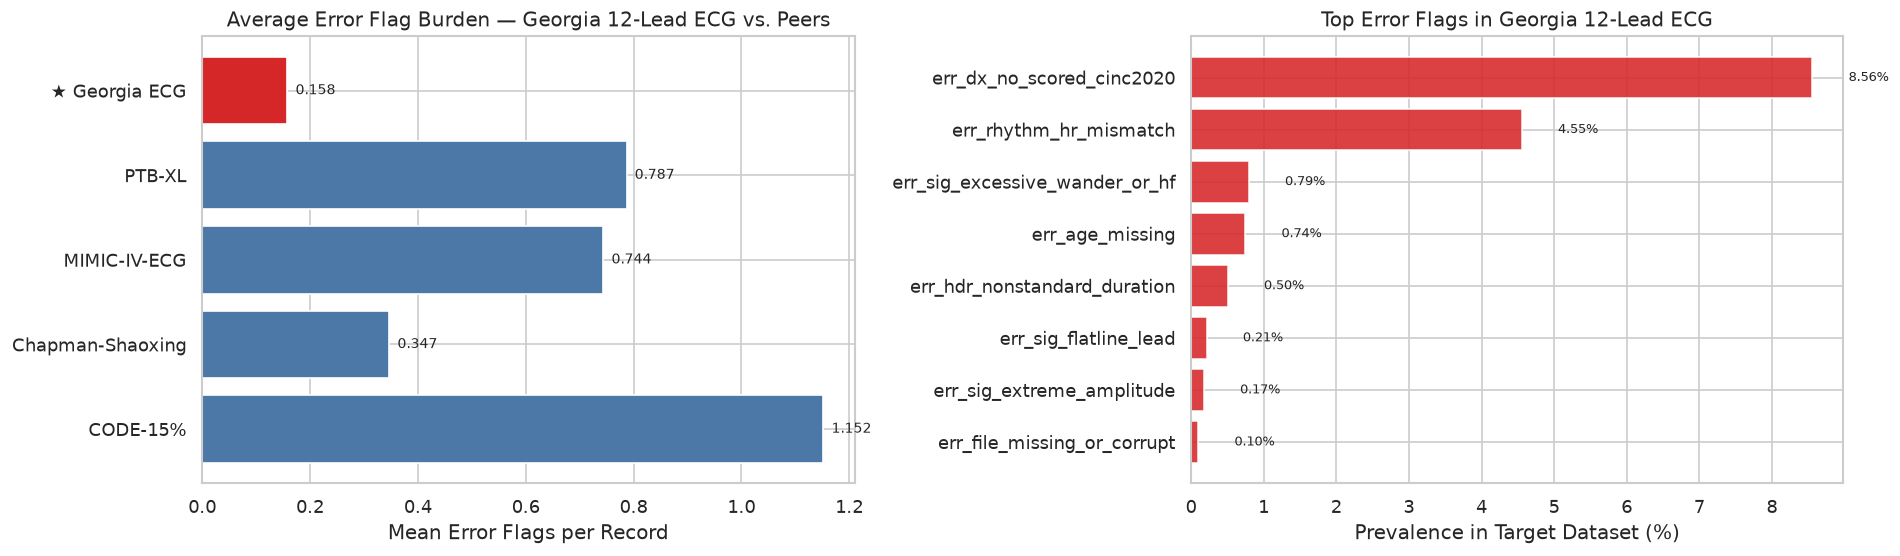

In [5]:
def universal_rates(key: str, df: pd.DataFrame) -> dict:
    cols = set(df.columns)
    def any_col(candidates):
        present = [c for c in candidates if c in cols]
        if not present:
            return 0.0
        return float(100 * (df[present].sum(axis=1) > 0).mean())

    return {
        "Dataset": f"★ {NAME_BY_KEY[key]}" if key == TARGET_KEY else NAME_BY_KEY[key],
        "Missing/Corrupt File %": round(any_col(["err_file_missing_or_corrupt", "err_file_missing_hdf5_part"]), 2),
        "Pediatric (<18) %": round(any_col(["err_age_pediatric", "err_rep_pediatric"]), 2),
        "Label/Rhythm Conflict %": round(any_col([
            "err_scp_norm_pathology_conflict", "err_rhythm_hr_mismatch",
            "err_dx_nsr_pathology_conflict", "err_dx_sr_arrhythmia_conflict",
            "err_lbl_af_with_sinus_rhythm", "err_lbl_rbbb_and_lbbb_conflict",
            "err_lbl_normal_with_abnormality", "err_lbl_sb_and_st_conflict",
            "err_rep_rhythm_hr_mismatch",
        ]), 2),
        "Mean Flags / Record": round(float(df["n_error_flags"].mean()), 3),
    }

univ_df = pd.DataFrame([universal_rates(k, err_tables[k]) for k in ORDER])
display(univ_df)

# Top error flags specifically in TARGET_DATASET
t_df = err_tables[TARGET_KEY]
flag_cols = [c for c in t_df.columns if c.startswith("err_")]
top_flags = (
    (100 * t_df[flag_cols].mean())
    .sort_values(ascending=False)
    .head(8)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

# Panel A: Mean error flags per record across datasets
bars = axes[0].barh(
    univ_df["Dataset"], univ_df["Mean Flags / Record"],
    color=[HIGHLIGHT_COLOR if k == TARGET_KEY else PEER_COLOR for k in ORDER],
)
axes[0].invert_yaxis()
axes[0].set_xlabel("Mean Error Flags per Record")
axes[0].set_title(f"Average Error Flag Burden — {TARGET_NAME} vs. Peers")
for b, v in zip(bars, univ_df["Mean Flags / Record"]):
    axes[0].text(v + 0.015, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", fontsize=8.5)

# Panel B: Top 8 flags in TARGET_DATASET
axes[1].barh(top_flags.index, top_flags.values, color=HIGHLIGHT_COLOR, alpha=0.88)
axes[1].invert_yaxis()
axes[1].set_xlabel("Prevalence in Target Dataset (%)")
axes[1].set_title(f"Top Error Flags in {TARGET_NAME}")
for i, v in enumerate(top_flags.values):
    axes[1].text(v + 0.5, i, f"{v:.2f}%", va="center", fontsize=8)

plt.tight_layout()
plt.show()


## 5. Side-by-Side Clean Lead-II Waveform Comparison (`0–5 s`)

Visual comparison of one `0_clean` Lead-II strip (`0–5 s`) from **Georgia 12-Lead ECG** (highlighted on top) against one `0_clean` Lead-II strip from each of the other four datasets.

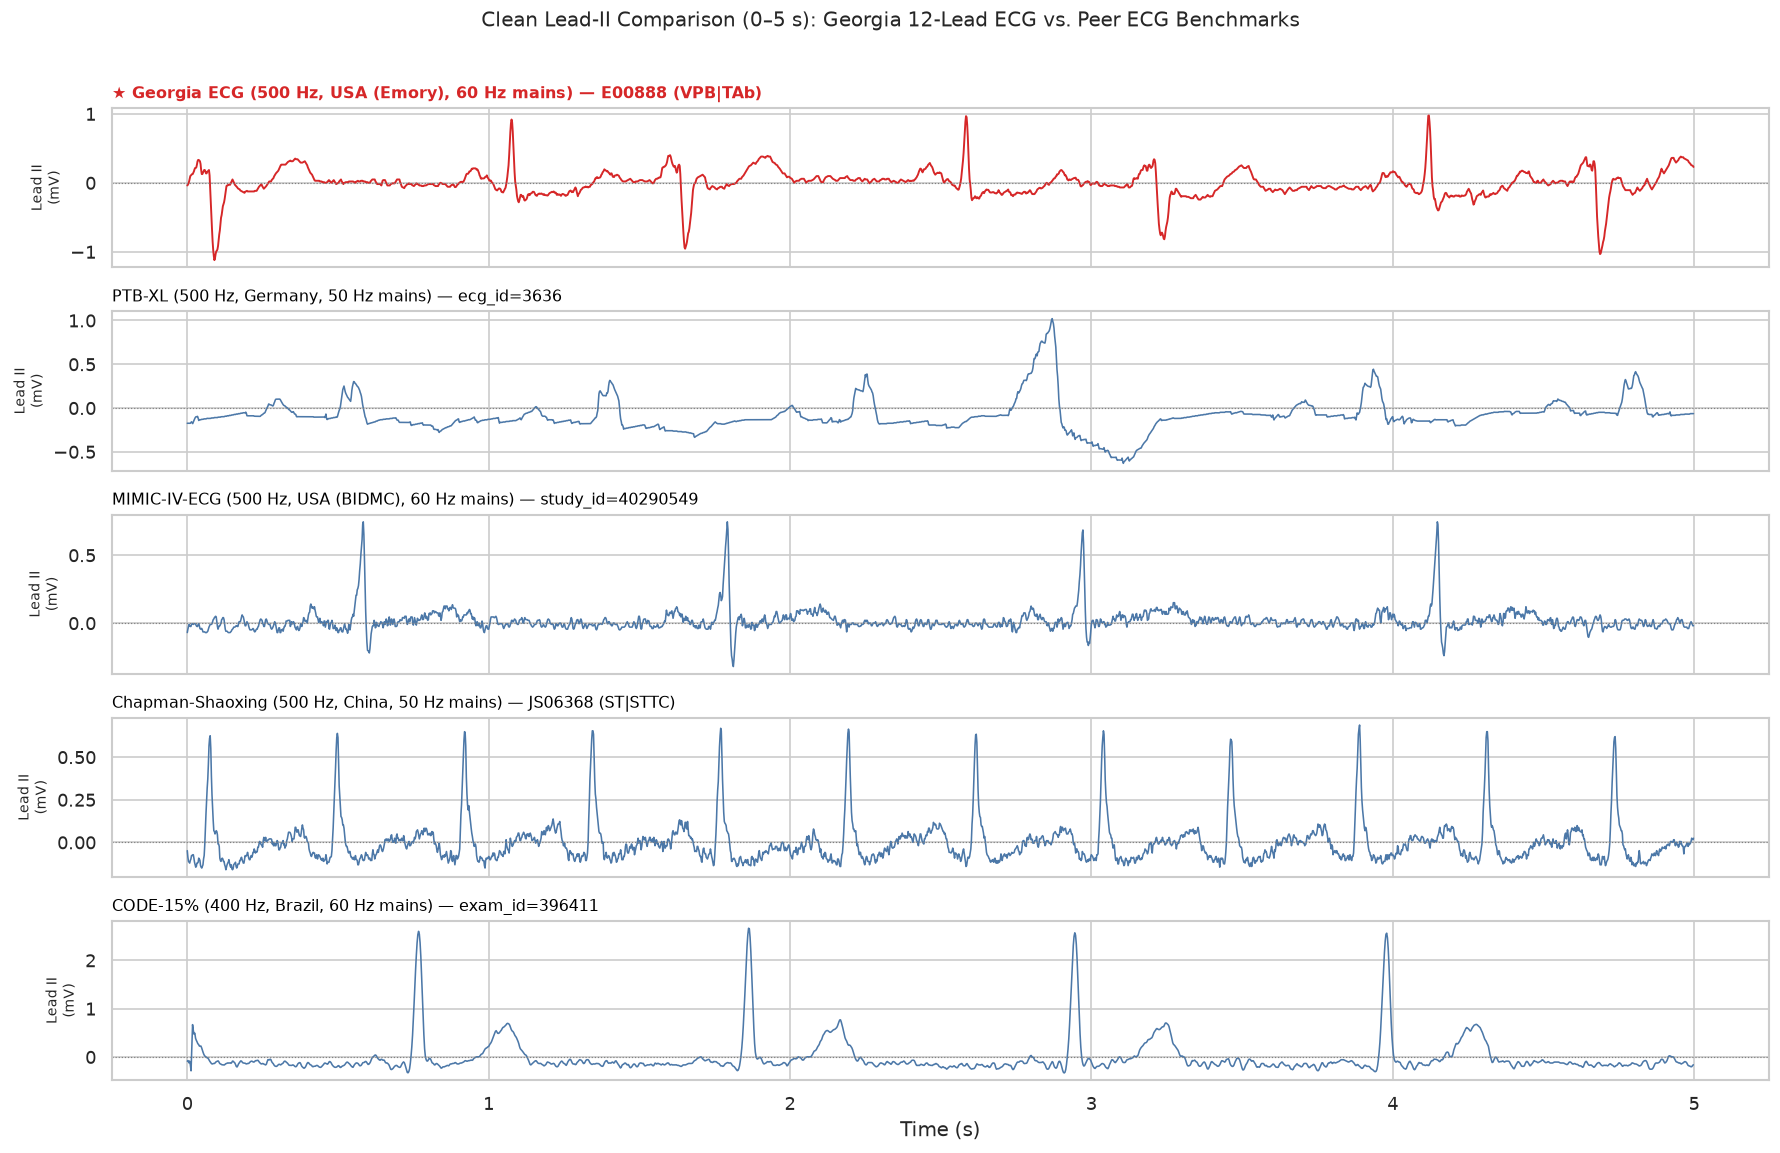

In [6]:
fig, axes = plt.subplots(len(ORDER), 1, figsize=(15, 9.5), sharex=True)

for ax, k in zip(axes, ORDER):
    sig, fs, rlbl = example_strips[k]
    n_pts = min(sig.shape[1], int(5.0 * fs))
    t = np.arange(n_pts) / float(fs)
    is_t = (k == TARGET_KEY)
    ax.plot(t, sig[1, :n_pts], color=HIGHLIGHT_COLOR if is_t else PEER_COLOR, lw=1.15 if is_t else 0.95)
    ax.axhline(0, color="gray", ls=":", lw=0.7)
    ax.set_ylabel("Lead II\n(mV)", fontsize=8.5)
    prefix = "★ " if is_t else ""
    ax.set_title(
        f"{prefix}{NAME_BY_KEY[k]} ({fs} Hz, {META_BY_KEY[k]['region']}, {META_BY_KEY[k]['mains_hz']} Hz mains) — {rlbl}",
        loc="left", fontsize=9.8, fontweight="bold" if is_t else "normal",
        color=HIGHLIGHT_COLOR if is_t else "black",
    )

axes[-1].set_xlabel("Time (s)")
fig.suptitle(f"Clean Lead-II Comparison (0–5 s): {TARGET_NAME} vs. Peer ECG Benchmarks", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()
